# Seminar. Practical aspects of diffusion models
## Part 3 — A 6B text-to-image model: Z-Image (≈35 min)

[Z-Image](https://huggingface.co/Tongyi-MAI/Z-Image) (Tongyi-MAI, Apache-2.0): undistilled base model, CFG and negative prompts supported. Mentioned in the lecture next to FLUX.2.

We drop the high-level `pipe(...)` call and write **our own 30-line sampler** in the lecture's notation, then use it to look at everything from the lecture at scale:

1. anatomy: text encoder / DiT / VAE
2. our sampler reproduces the official pipeline
3. the VAE: compression and reconstruction
4. the time shift at high resolution
5. what different timesteps do
6. CFG sweep + CLIP score
7. interval CFG
8. negative prompts
9. Euler vs Heun, number of steps
10. bonus: the distilled Z-Image-Turbo (8 steps, no CFG)

Needs ~40 GB of GPU memory. Times below are for one shared H100.

In [1]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '5')   # pick a free GPU (check nvidia-smi)
os.environ['HF_HUB_OFFLINE'] = '1'                   # all weights are cached: never wait for the network

import math, time
import numpy as np
import torch, torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import ZImagePipeline, ZImageTransformer2DModel, AutoencoderKL
from huggingface_hub import snapshot_download
import warnings, transformers, diffusers, huggingface_hub
warnings.filterwarnings('ignore')
for lib in (transformers, diffusers, huggingface_hub):
    lib.utils.logging.set_verbosity_error()

torch.set_num_threads(4)
dev, dtype = 'cuda', torch.bfloat16
plt.rcParams.update({'figure.dpi': 80})

t0 = time.time()
pipe = ZImagePipeline.from_pretrained('Tongyi-MAI/Z-Image', torch_dtype=dtype).to(dev)
pipe.set_progress_bar_config(disable=True)
print(f'loaded in {time.time() - t0:.0f}s')

def show(images, titles=None, cols=None, size=4.0, suptitle=None):
    cols = cols or len(images)
    rows = math.ceil(len(images) / cols)
    fig, axs = plt.subplots(rows, cols, figsize=(size * cols, size * rows), squeeze=False)
    for i, ax in enumerate(axs.flat):
        ax.axis('off')
        if i < len(images):
            ax.imshow(images[i])
            if titles: ax.set_title(titles[i], fontsize=11)
    if suptitle: fig.suptitle(suptitle, fontsize=13)
    plt.tight_layout(); plt.show()

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

loaded in 8s


## 1. Anatomy

In [2]:
def n_params(m):
    return sum(p.numel() for p in m.parameters()) / 1e9

for name, m in [('text encoder (Qwen3-4B LLM)', pipe.text_encoder), ('transformer (DiT)', pipe.transformer), ('VAE', pipe.vae)]:
    print(f'{name:30s} {n_params(m):6.2f}B params')
cfg = pipe.transformer.config
print(f"\nDiT: {cfg.n_layers} layers, dim {cfg.dim}, {cfg.n_heads} heads, patch {cfg.all_patch_size[0]}, latent channels {cfg.in_channels}")
print('\nOne DiT block:')
print(pipe.transformer.layers[0])

text encoder (Qwen3-4B LLM)      4.02B params
transformer (DiT)                6.15B params
VAE                              0.08B params

DiT: 30 layers, dim 3840, 30 heads, patch 2, latent channels 16

One DiT block:
ZImageTransformerBlock(
  (attention): Attention(
    (norm_q): RMSNorm()
    (norm_k): RMSNorm()
    (to_q): Linear(in_features=3840, out_features=3840, bias=False)
    (to_k): Linear(in_features=3840, out_features=3840, bias=False)
    (to_v): Linear(in_features=3840, out_features=3840, bias=False)
    (to_out): ModuleList(
      (0): Linear(in_features=3840, out_features=3840, bias=False)
      (1): Dropout(p=0.0, inplace=False)
    )
  )
  (feed_forward): FeedForward(
    (w1): Linear(in_features=3840, out_features=10240, bias=False)
    (w2): Linear(in_features=10240, out_features=3840, bias=False)
    (w3): Linear(in_features=3840, out_features=10240, bias=False)
  )
  (attention_norm1): RMSNorm()
  (ffn_norm1): RMSNorm()
  (attention_norm2): RMSNorm()
  (ffn_norm2

* **Text encoder** is a full LLM (Qwen3-4B, hidden states of the second-to-last layer). FLUX.2 made the same move (Mistral instead of CLIP+T5).
* **DiT** — *single-stream*: text tokens and image tokens are concatenated into **one sequence** and processed by shared blocks (a couple of modality-specific "refiner" blocks first). SD3/FLUX use MM-DiT (separate weights per modality in the double-stream blocks).
* **AdaLN**: `adaLN_modulation` maps the **timestep** embedding to scale/gate of each block — exactly the lecture's $\mathrm{AdaLN}(x,c,t)$. The text enters only via attention.
* Each 2×2 patch of the 16-channel latent is one token: a 1024×1024 image → 128×128 latent → **4096 image tokens**.

## 2. Our sampler

Lecture notation: $x_t = (1-t)x_0 + t\epsilon$, $v=\epsilon-x_0$, Euler from $t=1$ to $t=0$.

Z-Image internally feeds $1-t$ and predicts $-v$ — a 1-line conversion in `velocity`.
Its sampling grid is the lecture's shift $s(\alpha,t)$ with $\alpha=6$ (`scheduler.config.shift`).

In [3]:
print(pipe.scheduler.config)

@torch.no_grad()
def encode(prompts):
    """list[str] -> list of [L_i, 2560] text embeddings (variable length, no padding)."""
    return pipe._encode_prompt(list(prompts), device=dev)

@torch.no_grad()
def velocity(x, t, emb, model=None):
    """v_theta(x_t, t) = eps - x0 in the lecture convention. x: [B, 16, h, w], emb: list of B text embeddings."""
    model = model or pipe.transformer
    out = model(list(x.to(dtype).unsqueeze(2).unbind(0)), torch.full((len(x),), 1 - t, device=dev), emb, return_dict=False)[0]
    return -torch.stack(out).squeeze(2).float()

def shift_t(t, alpha):
    return alpha * t / (1 + (alpha - 1) * t)

@torch.no_grad()
def decode(z):
    z = z / pipe.vae.config.scaling_factor + pipe.vae.config.shift_factor
    img = pipe.vae.decode(z.to(pipe.vae.dtype)).sample
    return [Image.fromarray(((im.float().clamp(-1, 1) + 1) * 127.5).round().byte().permute(1, 2, 0).cpu().numpy()) for im in img]

@torch.no_grad()
def encode_image(img):
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1)[None].to(dev, pipe.vae.dtype) / 127.5 - 1
    z = pipe.vae.encode(x).latent_dist.mode()
    return ((z - pipe.vae.config.shift_factor) * pipe.vae.config.scaling_factor).float()

def initial_noise(seeds, size):
    return torch.stack([torch.randn(16, size // 8, size // 8, generator=torch.Generator().manual_seed(s)) for s in seeds]).to(dev)

@torch.no_grad()
def generate(prompt, w=5.0, steps=30, shift=6.0, neg='', seeds=(0,), size=768,
             interval=(0.0, 1.0), solver='euler', prompt_after=None, switch_step=None,
             x0_every=None, model=None, x=None):
    """Euler/Heun sampler with CFG.
    w            : CFG scale in the lecture's convention (w=1 -> no guidance). NB: diffusers' guidance_scale = w - 1.
    interval     : apply CFG only for t in [lo, hi]
    prompt_after : switch to this prompt from step `switch_step` on
    x0_every     : also return decoded x0-predictions every k steps
    """
    B = len(seeds)
    c, u = encode([prompt]) * B, encode([neg]) * B
    x = initial_noise(seeds, size) if x is None else x
    ts = shift_t(torch.linspace(1, 0, steps + 1), shift).tolist()

    def v_guided(x, t, c):
        if w == 1.0 or not (interval[0] <= t <= interval[1]):
            return velocity(x, t, c, model)
        v_c, v_u = velocity(torch.cat([x, x]), t, c + u, model).chunk(2)
        return v_u + w * (v_c - v_u)

    x0_preds = []
    for i in range(steps):
        if prompt_after is not None and i == switch_step:
            c = encode([prompt_after]) * B
        t, t_next = ts[i], ts[i + 1]
        v = v_guided(x, t, c)
        if x0_every and i % x0_every == 0:
            x0_preds.append((t, decode(x - t * v)))                  # x0_hat = x_t - t v
        if solver == 'heun' and t_next > 0:
            x_pred = x + (t_next - t) * v
            x = x + (t_next - t) / 2 * (v + v_guided(x_pred, t_next, c))
        else:
            x = x + (t_next - t) * v
    images = decode(x)
    return (images, x0_preds) if x0_every else images

FrozenDict({'num_train_timesteps': 1000, 'shift': 6.0, 'use_dynamic_shifting': False, 'base_shift': 0.5, 'max_shift': 1.15, 'base_image_seq_len': 256, 'max_image_seq_len': 4096, 'invert_sigmas': False, 'shift_terminal': None, 'use_karras_sigmas': False, 'use_exponential_sigmas': False, 'use_beta_sigmas': False, 'time_shift_type': 'exponential', 'stochastic_sampling': False, '_use_default_values': ['max_shift', 'stochastic_sampling', 'use_karras_sigmas', 'use_exponential_sigmas', 'base_shift', 'time_shift_type', 'invert_sigmas', 'max_image_seq_len', 'use_beta_sigmas', 'shift_terminal', 'base_image_seq_len'], '_class_name': 'FlowMatchEulerDiscreteScheduler', '_diffusers_version': '0.37.0.dev0'})


### 2.1 Sanity check: our loop vs `pipe(...)`
Same initial noise, same grid. Note the scale conversion: our $w=5$ ⇔ diffusers `guidance_scale=4`.

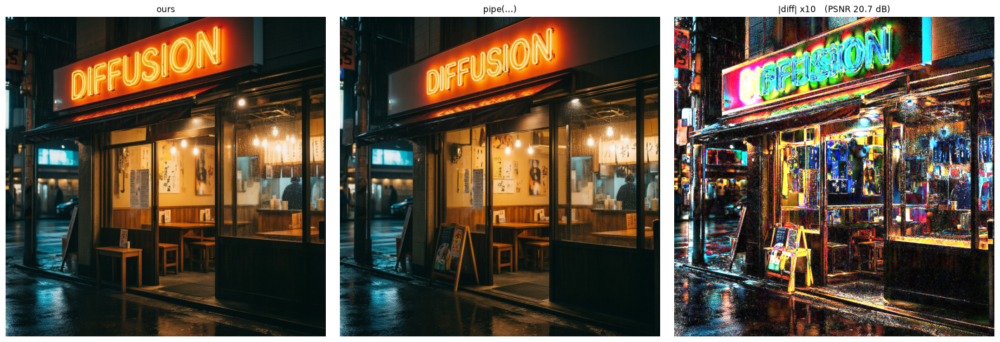

1024x1024, 30 steps, CFG: 17.6s


In [4]:
prompt = 'A cozy ramen shop at night in the rain, glowing neon sign with the text "DIFFUSION", cinematic photo, 35mm'
size = 1024
t0 = time.time()
ours = generate(prompt, w=5.0, steps=30, seeds=(0,), size=size)[0]
t_ours = time.time() - t0
x_init = initial_noise((0,), size)
ref = pipe(prompt, height=size, width=size, num_inference_steps=30, guidance_scale=4.0, latents=x_init.clone()).images[0]

diff = np.abs(np.asarray(ours, dtype=np.float32) - np.asarray(ref, dtype=np.float32))
psnr = 10 * np.log10(255 ** 2 / (diff ** 2).mean())
show([ours, ref, Image.fromarray(np.clip(diff * 10, 0, 255).astype(np.uint8))],
     ['ours', 'pipe(...)', f'|diff| x10   (PSNR {psnr:.1f} dB)'], size=6)
print(f'{size}x{size}, 30 steps, CFG: {t_ours:.1f}s')

Visually identical; the residual (~29 dB) is bf16 / attention-kernel numerics accumulated over 30 steps.

## 3. The VAE

Lecture: *the AE takes care of imperceptible noise and high-frequency details → low-dimensional latent space → higher learnability.* Requirements: quality, learnability, compression.

image (1024, 1024, 3) = 3,145,728 numbers
latent (16, 128, 128) = 262,144 numbers  -> compression x12
tokens for the DiT (2x2 patches): 4096
scaled latent: mean -0.194, std 0.960  (scaling/shift factors make it ~N(0,1)-like)


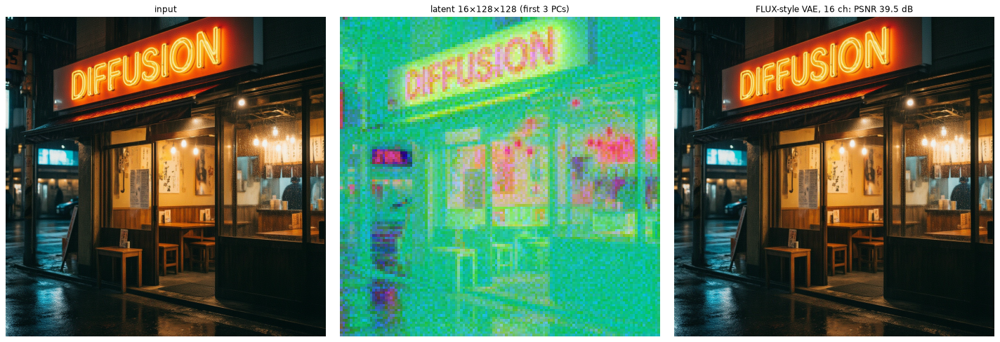

In [5]:
hero = ours
z = encode_image(hero)
rec = decode(z)[0]
print(f'image {tuple(np.array(hero).shape)} = {np.array(hero).size:,} numbers')
print(f'latent {tuple(z.shape[1:])} = {z[0].numel():,} numbers  -> compression x{np.array(hero).size / z[0].numel():.0f}')
print(f'tokens for the DiT (2x2 patches): {z.shape[2] // 2 * z.shape[3] // 2}')
print(f'scaled latent: mean {z.mean():.3f}, std {z.std():.3f}  (scaling/shift factors make it ~N(0,1)-like)')

def psnr_img(a, b):
    a, b = np.asarray(a, dtype=np.float32), np.asarray(b, dtype=np.float32)
    return 10 * np.log10(255 ** 2 / ((a - b) ** 2).mean())

# latent visualised as RGB: first 3 principal components over the 16 channels
zz = z[0].reshape(16, -1).T
zz = zz - zz.mean(0)
pcs = torch.linalg.svd(zz, full_matrices=False).Vh[:3]
rgb = (zz @ pcs.T).reshape(z.shape[2], z.shape[3], 3)
rgb = ((rgb - rgb.amin((0, 1))) / (rgb.amax((0, 1)) - rgb.amin((0, 1)))).cpu().numpy()
show([hero, rgb, rec], ['input', 'latent 16×128×128 (first 3 PCs)', f'FLUX-style VAE, 16 ch: PSNR {psnr_img(hero, rec):.1f} dB'], size=6)

Compare with the older **SD-VAE** (4 channels, same 8× downsampling → 48× compression). Zoom into the small text.

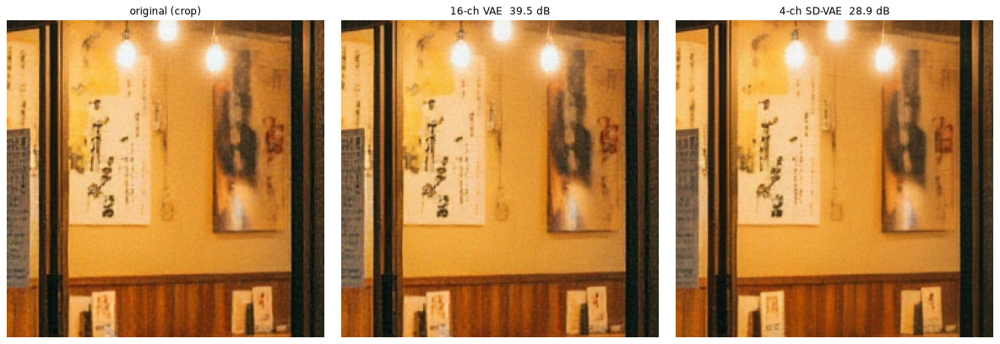

In [6]:
sd_vae = AutoencoderKL.from_pretrained('stabilityai/sd-vae-ft-mse', torch_dtype=torch.float32).to(dev)
with torch.no_grad():
    xin = torch.from_numpy(np.array(hero)).permute(2, 0, 1)[None].to(dev).float() / 127.5 - 1
    rec_sd = sd_vae.decode(sd_vae.encode(xin).latent_dist.mode()).sample
rec_sd = Image.fromarray(((rec_sd[0].clamp(-1, 1) + 1) * 127.5).round().byte().permute(1, 2, 0).cpu().numpy())

box = (440, 400, 696, 656)          # small details: posters, lamps (adjust for your image)
show([hero.crop(box), rec.crop(box), rec_sd.crop(box)],
     ['original (crop)', f'16-ch VAE  {psnr_img(hero, rec):.1f} dB', f'4-ch SD-VAE  {psnr_img(hero, rec_sd):.1f} dB'], size=5)
del sd_vae; torch.cuda.empty_cache()

## 4. The time shift at high resolution

Notebook 2 showed that at the same $t$ a high-resolution image is effectively less noisy. Z-Image samples with $\alpha=6$ at 1024².
What if we ignore this and use the uniform grid ($\alpha=1$)? Same seed, 20 steps, ~1 min.

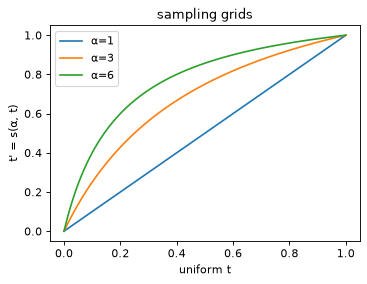

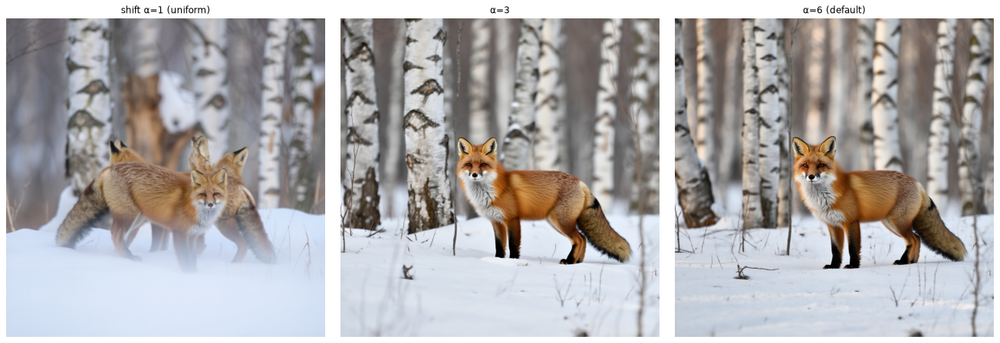

In [7]:
tt = torch.linspace(0, 1, 100)
plt.figure(figsize=(5, 3.5))
for a in [1, 3, 6]:
    plt.plot(tt, shift_t(tt, a), label=f'α={a}')
plt.xlabel('uniform t'); plt.ylabel("t' = s(α, t)"); plt.legend(); plt.title('sampling grids'); plt.show()

prompt_shift = 'A red fox standing in a snowy birch forest, morning light, wildlife photography'
imgs = [generate(prompt_shift, shift=a, steps=20, seeds=(1,), size=1024)[0] for a in [1.0, 3.0, 6.0]]
show(imgs, ['shift α=1 (uniform)', 'α=3', 'α=6 (default)'], size=5.5)

With the uniform grid the very first steps are too large: the global structure is not settled in time and the result is ghosted (two foxes blended). Same lesson as in the toy notebook: the high/intermediate-noise steps decide the composition.

## 5. What do the timesteps do?

### 5.1 The $\hat x_0$ prediction along the trajectory
$\hat x_0 = x_t - t\,v_\theta(x_t, t)$ — what the model "thinks" the final image is at each step. Lecture: early = easy (blurry average), intermediate = difficult and important (composition), late = easy (details).

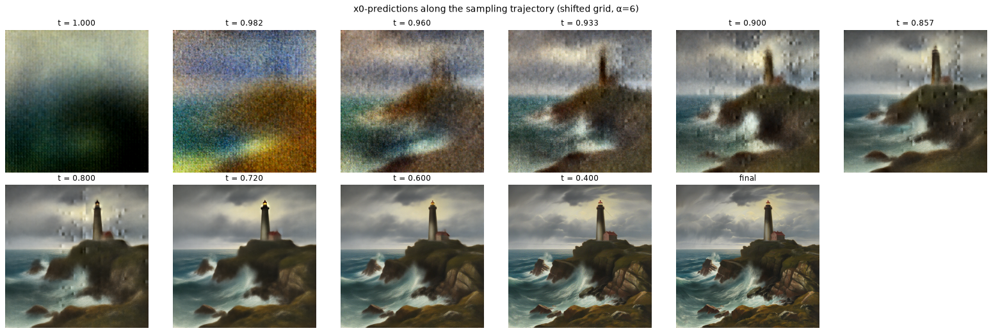

In [8]:
img, x0s = generate('A lighthouse on a rocky cliff above a stormy sea, oil painting', steps=30, seeds=(3,), size=768, x0_every=3)
show([im[0] for _, im in x0s] + [img[0]], [f't = {t:.3f}' for t, _ in x0s] + ['final'], cols=6, size=3.3,
     suptitle='x0-predictions along the sampling trajectory (shifted grid, α=6)')

### 5.2 Switching the prompt mid-way

Start with prompt A and switch to prompt B at step $k$ (of 30). Where is the layout decided, where the object identity, where the details? ~1.5 min.

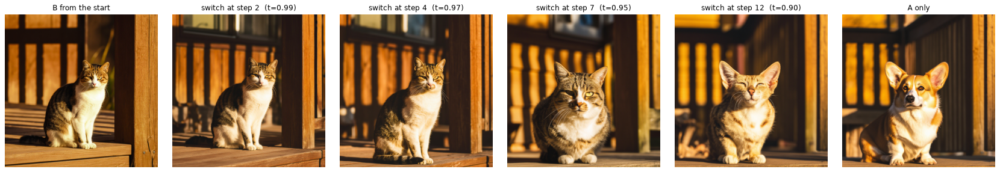

In [9]:
A = 'A photo of a corgi sitting on a wooden porch, golden hour'
B = 'A photo of a cat sitting on a wooden porch, golden hour'
ks = [0, 2, 4, 7, 12, 30]
imgs = [generate(A, prompt_after=B, switch_step=k, steps=30, seeds=(5,), size=768)[0] for k in ks]
ts = shift_t(torch.linspace(1, 0, 31), 6.0)
show(imgs, [f'switch at step {k}  (t={ts[k]:.2f})' if 0 < k < 30 else ('B from the start' if k == 0 else 'A only') for k in ks], cols=6, size=3.5)

## 6. CFG sweep + CLIP score

$v_{CFG} = v(x\mid\varnothing) + w\,(v(x\mid c) - v(x\mid\varnothing))$. The lecture's turtles: low diversity and oversaturation at large $w$.

Quality evaluation: **CLIP score** $=\cos(f_{text}, f_{image})$ (prompt alignment) and a crude **diversity** = $1-$ mean pairwise cosine between the CLIP image embeddings of different seeds. 512², 25 steps, ~2 min.

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

84s


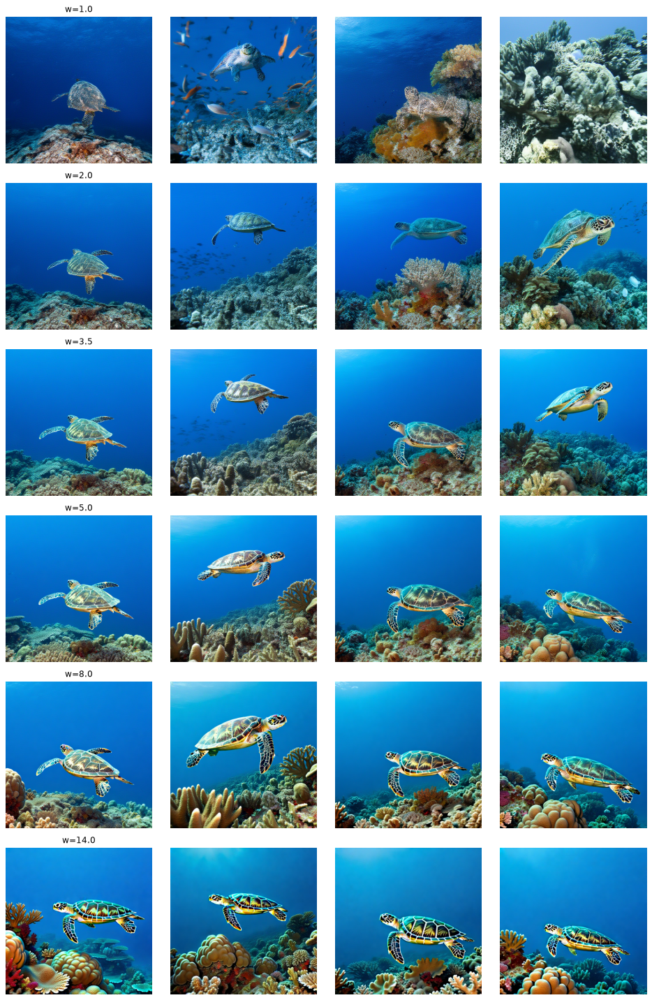

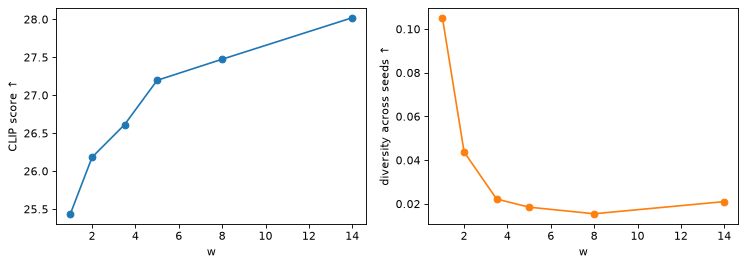

In [10]:
from transformers import CLIPModel, CLIPProcessor
clip = CLIPModel.from_pretrained('openai/clip-vit-large-patch14', torch_dtype=torch.float16).to(dev).eval()
clip_proc = CLIPProcessor.from_pretrained('openai/clip-vit-large-patch14')

@torch.no_grad()
def clip_embed(images=None, text=None):
    if images is not None:
        f = clip.get_image_features(**clip_proc(images=images, return_tensors='pt').to(dev, torch.float16))
    else:
        f = clip.get_text_features(**clip_proc(text=[text], return_tensors='pt', padding=True).to(dev))
    f = f if torch.is_tensor(f) else f.pooler_output
    return F.normalize(f.float(), dim=-1)

prompt_cfg = 'A sea turtle swimming over a coral reef, underwater photo'
ws, seeds = [1.0, 2.0, 3.5, 5.0, 8.0, 14.0], (0, 1, 2, 3)
t0 = time.time()
rows = {w: generate(prompt_cfg, w=w, steps=25, seeds=seeds, size=512) for w in ws}
print(f'{time.time() - t0:.0f}s')

text_f = clip_embed(text=prompt_cfg)
clip_scores, diversity = [], []
for w in ws:
    img_f = clip_embed(images=rows[w])
    clip_scores.append(100 * (img_f @ text_f.T).mean().item())
    sim = img_f @ img_f.T
    diversity.append(1 - sim[~torch.eye(len(seeds), dtype=bool, device=dev)].mean().item())

show([im for w in ws for im in rows[w]], [f'w={w}' if i == 0 else '' for w in ws for i in range(len(seeds))], cols=len(seeds), size=3)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.5))
axs[0].plot(ws, clip_scores, 'o-'); axs[0].set_xlabel('w'); axs[0].set_ylabel('CLIP score ↑')
axs[1].plot(ws, diversity, 'o-', c='tab:orange'); axs[1].set_xlabel('w'); axs[1].set_ylabel('diversity across seeds ↑')
plt.show()

Things to discuss:
* $w=1$ (no guidance) is noticeably worse: the turtle is sometimes missing — CFG is critical in practice.
* Large $w$: saturated "cartoon" colours and near-identical images (diversity collapses already at $w\approx3$).
* The CLIP score **keeps growing** even at $w=14$, where the images clearly look worse. No automated metric is fully reliable → human side-by-side evaluation.

## 7. Interval CFG

Guidance only for $t\in[t_{lo}, t_{hi}]$: no guidance at high noise (keeps diversity and avoids mode dropping) and none at the very end (saves compute, nothing changes there). Lecture's raccoon. ~1.5 min.

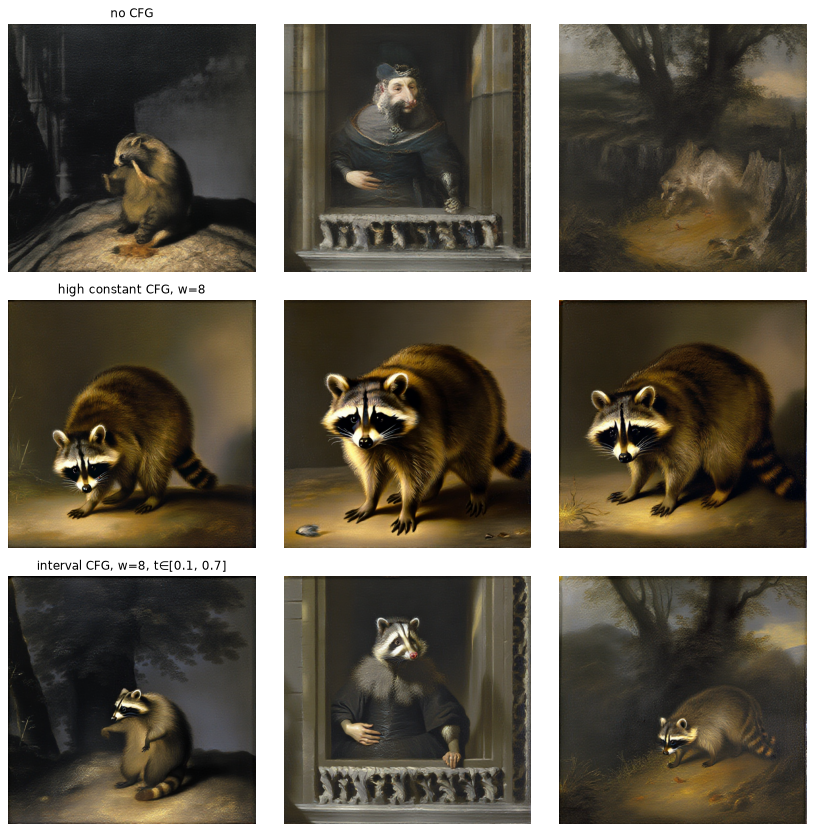

In [11]:
prompt_iv = 'Rembrandt painting of a raccoon'
seeds = (0, 1, 2)
configs = [(1.0, (0, 1), 'no CFG'), (8.0, (0, 1), 'high constant CFG, w=8'), (8.0, (0.1, 0.7), 'interval CFG, w=8, t∈[0.1, 0.7]')]
imgs, titles = [], []
for w, iv, name in configs:
    imgs += generate(prompt_iv, w=w, interval=iv, steps=25, seeds=seeds, size=512)
    titles += [name] + [''] * (len(seeds) - 1)
show(imgs, titles, cols=len(seeds), size=3.5)

## 8. Negative prompts

The unconditional branch $v(x,\varnothing)$ can be replaced by anything we do **not** want: $v(x, c^-)$. The lecture's Garfield example.

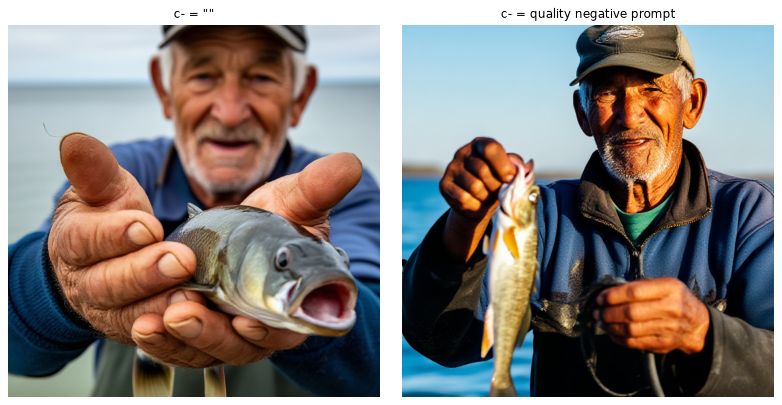

In [13]:
NEG_QUALITY = ('low quality, blurry, out of focus, low resolution, pixelated, jpeg artifacts, noisy, oversharpened, '
               'bad anatomy, bad proportions, deformed, extra fingers, missing fingers, fused fingers, '
               'poorly drawn face, distorted face, watermark, 3d render, plastic skin, overexposed, underexposed')
p = 'A close-up portrait of an old fisherman holding a fish with both hands'
imgs = generate(p, w=5.0, steps=25, seeds=(7,), size=640) + generate(p, w=5.0, neg=NEG_QUALITY, steps=25, seeds=(7,), size=640)
show(imgs, ['c- = ""', 'c- = quality negative prompt'], size=5)

## 9. Solvers: Euler vs Heun at equal NFE

Heun uses 2 evaluations per step (×2 again for CFG). Compare at the same number of function evaluations. ~1.5 min.

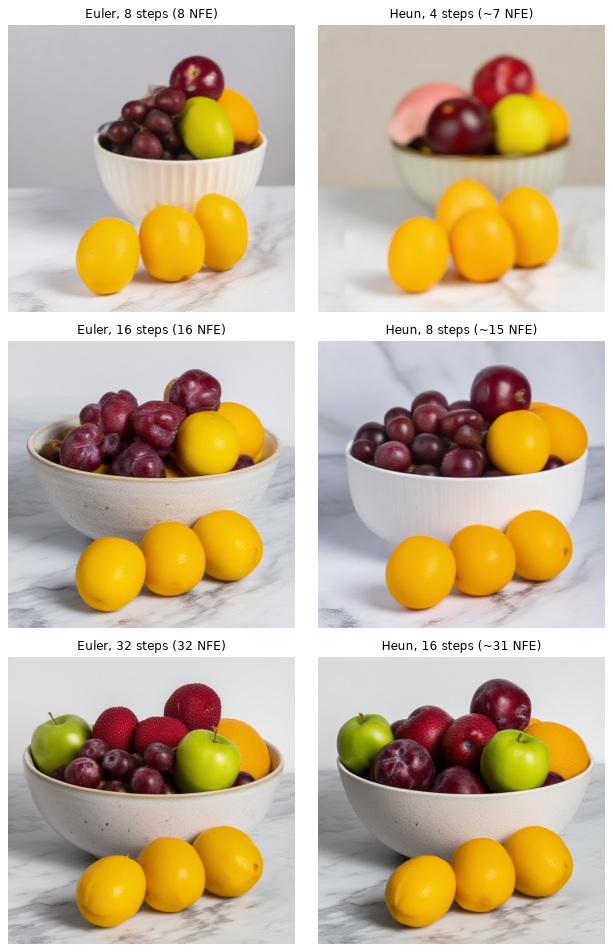

In [14]:
p = 'A bowl of fresh fruit on a marble table, studio photo'
imgs, titles = [], []
for nfe in [8, 16, 32]:
    imgs += generate(p, steps=nfe, seeds=(2,), size=512, solver='euler')
    imgs += generate(p, steps=nfe // 2, seeds=(2,), size=512, solver='heun')
    titles += [f'Euler, {nfe} steps ({nfe} NFE)', f'Heun, {nfe // 2} steps (~{nfe - 1} NFE)']
show(imgs, titles, cols=2, size=4)

At equal compute Heun is not better here (at 8 NFE it is even blurrier). A higher-order method only pays off when each step is accurate enough; with very few steps the error is dominated by the trajectory curvature. In practice flow models use Euler with a good (shifted) grid, and few-step generation comes from **distillation** instead.

## 10. Bonus: a distilled model — Z-Image-Turbo

Same text encoder and VAE, a distilled DiT: **8 steps, no CFG** (guidance is baked in). Distillation makes the trajectories effectively straight → few steps.
Cost: base model 30 steps × 2 (CFG) = 60 NFE vs Turbo 8 NFE. Typical price: lower diversity (the model card says so too).

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

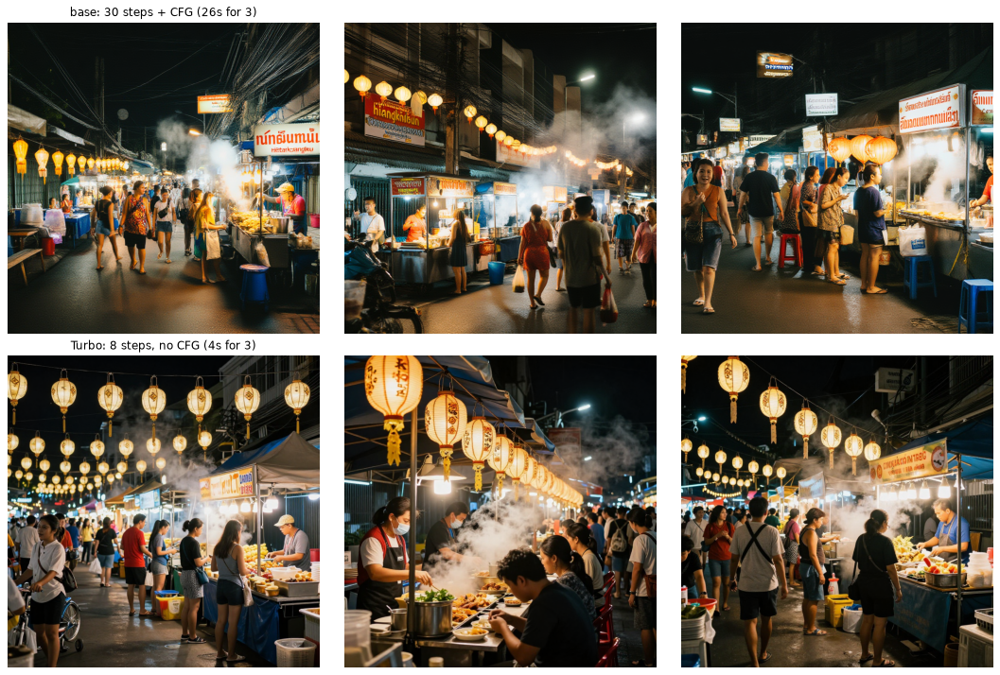

In [7]:
turbo_path = snapshot_download('Tongyi-MAI/Z-Image-Turbo', allow_patterns=['transformer/*'])
turbo = ZImageTransformer2DModel.from_pretrained(turbo_path, subfolder='transformer', torch_dtype=dtype).to(dev)
p = 'A street food market in Bangkok at night, people, lanterns, steam, photo'
seeds = (0, 1, 2)

t0 = time.time(); base_imgs = generate(p, w=5.0, steps=30, seeds=seeds, size=768); t_base = time.time() - t0
t0 = time.time(); turbo_imgs = generate(p, w=1.0, steps=8, shift=3.0, seeds=seeds, size=768, model=turbo); t_turbo = time.time() - t0
show(base_imgs + turbo_imgs, [f'base: 30 steps + CFG ({t_base:.0f}s for 3)', '', '', f'Turbo: 8 steps, no CFG ({t_turbo:.0f}s for 3)', '', ''], cols=3, size=4.5)

## Playground
Change the prompt / $w$ / steps / shift / interval / negative prompt and generate.

In [25]:
p = "Nikita is teaching Mishan, two strong men, bearded, "
turbo_imgs = generate(p, w=1.0, steps=8, shift=3.0, seeds=seeds, size=768, model=turbo)

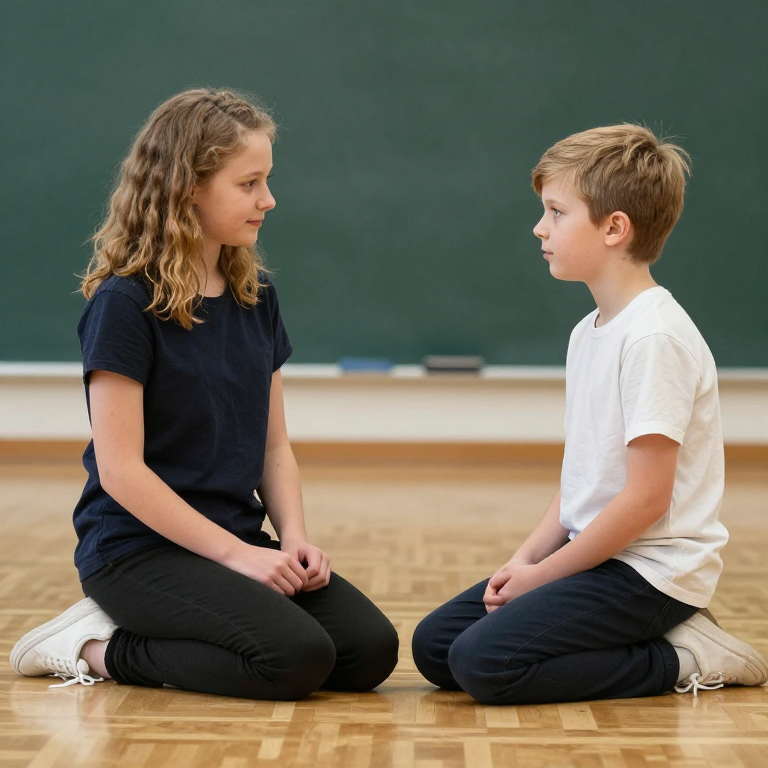

In [28]:
turbo_imgs[2]